# 🩸 Proje 2 · Bölüm 2 — İlk modelimiz: Lojistik regresyon
**Seviye: Orta**

**Lojistik regresyon**, tıpta onlarca yıldır kullanılan bir istatistik yöntemidir; aynı zamanda en temel makine öğrenmesi modelidir. Her değişkene bir **ağırlık** verir; ağırlıklı toplam bir **olasılığa** (0–1) çevrilir.

Makine öğrenmesinin temel kuralı: **Modeli eğittiğin veriyle test etme!** Bu yüzden veriyi ikiye ayırıyoruz:
* **Eğitim seti (%75):** model buradan öğrenir
* **Test seti (%25):** "hiç görülmemiş hastalar" — gerçek başarıyı burada ölçeriz

In [1]:
# Google Colab'da çalışıyorsanız proje klasörünü (zip) yükleyin
import os, sys
if "google.colab" in sys.modules and not os.path.exists("veri"):
    from google.colab import files
    print("Lütfen 02_Diyabet.zip dosyasını seçin"); files.upload()
    !unzip -q -o 02_Diyabet.zip
    %cd 02_Diyabet
print("Çalışma klasörü:", os.getcwd())

Çalışma klasörü: /home/claude/SaglikYZ/02_Diyabet


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, json, warnings
warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid", font_scale=0.9)
OZELLIKLER = ["Gebelik", "Glukoz", "KanBasinci", "DeriKalinligi", "Insulin", "VKI", "SoygecmisSkoru", "Yas"]

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay

veri = pd.read_csv("veri/diyabet_temiz.csv")
X, y = veri[OZELLIKLER], veri["Diyabet"].values
X_egt, X_tst, y_egt, y_tst = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(f"Eğitim: {len(X_egt)} kişi (diyabet %{100*y_egt.mean():.0f}) | Test: {len(X_tst)} kişi (diyabet %{100*y_tst.mean():.0f})")
pd.Series({"egitim": X_egt.index.tolist(), "test": X_tst.index.tolist()}).to_json("islenmis/bolunme.json")

Eğitim: 576 kişi (diyabet %35) | Test: 192 kişi (diyabet %35)


## 1. Basit bir "hekim kuralı" ile başlayalım (karşılaştırma için)
Bir modelin değerli olup olmadığını anlamak için önce basit bir kuralla karşılaştırırız: **"2. saat glukozu ≥ 140 mg/dL ise riskli"**.

In [3]:
def metrikler(y_gercek, tahmin, olasilik=None, ad=""):
    tn, fp, fn, tp = confusion_matrix(y_gercek, tahmin).ravel()
    return {"Yöntem": ad, "AUC": roc_auc_score(y_gercek, olasilik) if olasilik is not None else np.nan,
            "Doğruluk": (tp + tn) / len(y_gercek), "Duyarlılık": tp / (tp + fn), "Özgüllük": tn / (tn + fp),
            "PPD": tp / (tp + fp), "NPD": tn / (tn + fn)}

kural = (X_tst["Glukoz"].fillna(X_egt["Glukoz"].median()) >= 140).astype(int)
sonuclar = [metrikler(y_tst, kural, X_tst["Glukoz"].fillna(117), "Kural: Glukoz ≥ 140")]
pd.DataFrame(sonuclar).set_index("Yöntem").round(3)

,AUC,Doğruluk,Duyarlılık,Özgüllük,PPD,NPD
Yöntem,,,,,,
Kural: Glukoz ≥ 140,0.777,0.719,0.463,0.856,0.633,0.748


## 2. Lojistik regresyon modeli: 3 adımlı bir "boru hattı" (pipeline)
1. **Eksikleri doldur** (eğitim setinin medyanıyla)
2. **Standartlaştır** (her değişkeni ortalama 0, standart sapma 1 olacak şekilde ölçekle → ağırlıklar karşılaştırılabilir olur)
3. **Lojistik regresyon**

> Neden boru hattı? Doldurma ve ölçekleme değerleri **yalnızca eğitim setinden** öğrenilmeli. Test setinin bilgisi eğitime sızarsa (*veri sızıntısı*) başarı olduğundan yüksek görünür.

In [4]:
model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_egt, y_egt)
p_tst = model.predict_proba(X_tst)[:, 1]
sonuclar.append(metrikler(y_tst, (p_tst >= 0.5).astype(int), p_tst, "Lojistik regresyon (eşik 0,5)"))
pd.DataFrame(sonuclar).set_index("Yöntem").round(3)

,AUC,Doğruluk,Duyarlılık,Özgüllük,PPD,NPD
Yöntem,,,,,,
Kural: Glukoz ≥ 140,0.777,0.719,0.463,0.856,0.633,0.748
"Lojistik regresyon (eşik 0,5)",0.824,0.724,0.507,0.840,0.630,0.761


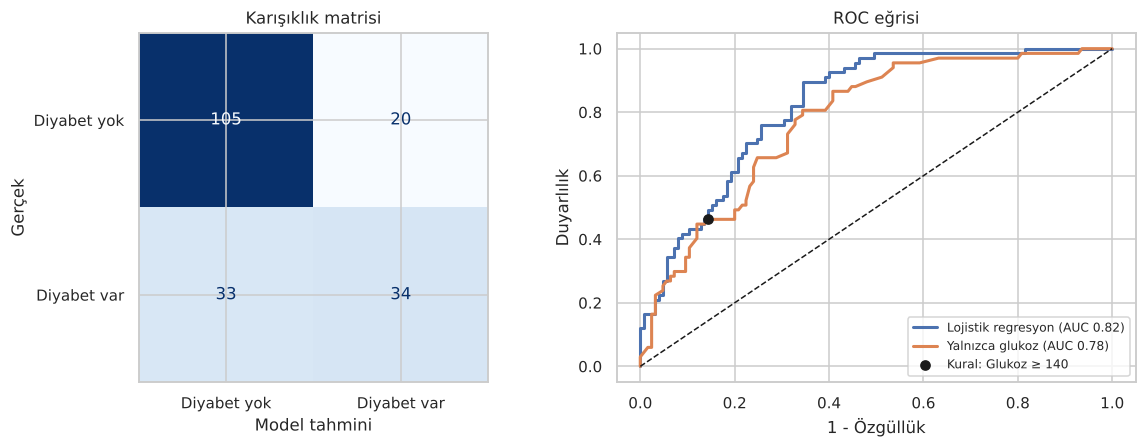

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_tst, p_tst >= 0.5), display_labels=["Diyabet yok", "Diyabet var"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_xlabel("Model tahmini"); ax[0].set_ylabel("Gerçek"); ax[0].set_title("Karışıklık matrisi")
for ad, sk in [("Lojistik regresyon", p_tst), ("Yalnızca glukoz", X_tst["Glukoz"].fillna(117))]:
    fpr, tpr, _ = roc_curve(y_tst, sk); ax[1].plot(fpr, tpr, lw=2, label=f"{ad} (AUC {roc_auc_score(y_tst, sk):.2f})")
k = metrikler(y_tst, kural, None); ax[1].scatter(1 - k["Özgüllük"], k["Duyarlılık"], c="k", zorder=5, label="Kural: Glukoz ≥ 140")
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_xlabel("1 - Özgüllük"); ax[1].set_ylabel("Duyarlılık"); ax[1].legend(fontsize=8); ax[1].set_title("ROC eğrisi")
plt.tight_layout(); plt.show()

**Karışıklık matrisini okumak:**
* Sol üst: diyabeti olmayan ve model de "yok" dedi ✅ (doğru negatif)
* Sağ alt: diyabeti olan ve model de "var" dedi ✅ (doğru pozitif)
* Sağ üst: **yanlış alarm** (yanlış pozitif) → gereksiz tetkik, kaygı
* Sol alt: **kaçırılan hasta** (yanlış negatif) → tedavide gecikme

## 3. Eşik bir klinik tercihtir
Bir **tarama** uygulamasında hastayı kaçırmamak daha önemlidir → eşiği düşürürüz.

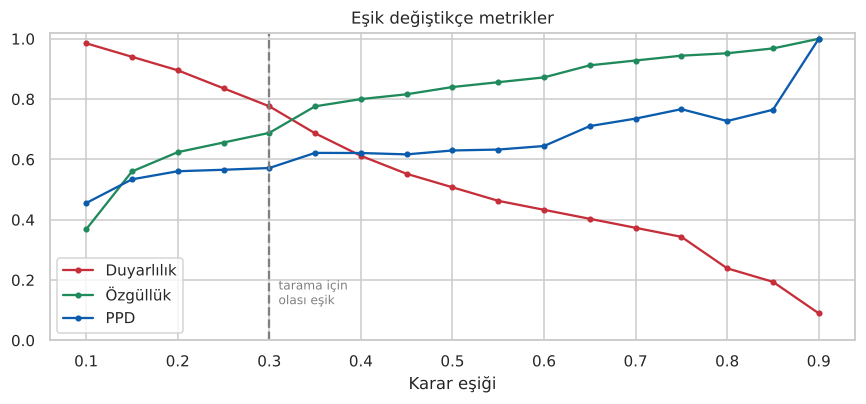

,Duyarlılık,Özgüllük,PPD,NPD
Yöntem,,,,
0.2,0.90,0.62,0.56,0.92
0.3,0.78,0.69,0.57,0.85
0.4,0.61,0.80,0.62,0.79
0.5,0.51,0.84,0.63,0.76
0.6,0.43,0.87,0.64,0.74


In [6]:
esikler = np.arange(0.1, 0.91, 0.05)
d = pd.DataFrame([metrikler(y_tst, (p_tst >= e).astype(int), None, round(e, 2)) for e in esikler]).set_index("Yöntem")
fig, ax = plt.subplots(figsize=(8, 3.8))
for s, c in [("Duyarlılık", "#c62f3a"), ("Özgüllük", "#1f8a5b"), ("PPD", "#0b5cad")]:
    ax.plot(esikler, d[s], "-o", ms=3, label=s, color=c)
ax.axvline(0.3, ls="--", c="gray"); ax.text(0.31, 0.12, "tarama için\nolası eşik", fontsize=8, color="gray")
ax.set_xlabel("Karar eşiği"); ax.set_ylim(0, 1.02); ax.legend(); ax.set_title("Eşik değiştikçe metrikler"); plt.tight_layout(); plt.show()
d.loc[[0.2, 0.3, 0.4, 0.5, 0.6], ["Duyarlılık", "Özgüllük", "PPD", "NPD"]].round(2)

## 4. Model neyi önemsiyor? (Ağırlıklar ve olasılık oranları)
Standartlaştırılmış verilerde katsayılar doğrudan karşılaştırılabilir. **Olasılık oranı (OR)**: değişken 1 standart sapma arttığında diyabet odds'unun kaç katına çıktığı.

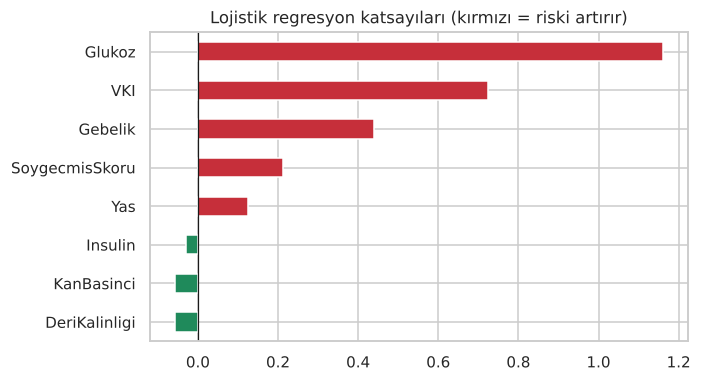

,katsayı,OR (1 SD artış),1 SD =
DeriKalinligi,-0.06,0.94,8.82
KanBasinci,-0.06,0.94,12.25
Insulin,-0.03,0.97,78.63
Yas,0.13,1.13,11.87
SoygecmisSkoru,0.21,1.24,0.33
Gebelik,0.44,1.55,3.31
VKI,0.72,2.06,6.74
Glukoz,1.16,3.19,30.10


In [7]:
lr = model[-1]; olcek = model[1]
katsayi = pd.DataFrame({"katsayı": lr.coef_[0], "OR (1 SD artış)": np.exp(lr.coef_[0]), "1 SD =": olcek.scale_}, index=OZELLIKLER).sort_values("katsayı")
katsayi["katsayı"].plot.barh(color=np.where(katsayi["katsayı"] > 0, "#c62f3a", "#1f8a5b"), figsize=(6.5, 3.6))
plt.axvline(0, c="k", lw=.8); plt.title("Lojistik regresyon katsayıları (kırmızı = riski artırır)"); plt.tight_layout(); plt.show()
katsayi.round(2)

In [8]:
pd.DataFrame(sonuclar).to_csv("islenmis/model_2_2_sonuclar.csv", index=False)

## ✅ Çıkarımlar
* Basit **glukoz kuralı** bile güçlüdür; makine öğrenmesi modelinin ona ne kattığını **dürüstçe** göstermek gerekir.
* Glukoz, VKİ, yaş ve soygeçmiş skoru riski en çok artıran değişkenler — klinik bilgiyle uyumlu ✔️ (Model klinik bilgiyle çelişseydi bu bir **uyarı işareti** olurdu.)
* Eşik, kullanım amacına (tarama mı, tanı mı?) göre **hekimle birlikte** seçilmelidir.